In [5]:
# set kernel to python 3.8 for running this notebook (non hyperspectral right now)

#reference url: https://github.com/NielsRogge/Transformers-Tutorials/blob/master/DINOv2/Train_a_linear_classifier_on_top_of_DINOv2_for_semantic_segmentation.ipynb 

!pip install albumentations
!pip install transformers
!pip install evaluate
!apt-get install gdal-bin -y
!pip install GDAL

Reading package lists... Done
Building dependency tree       
Reading state information... Done
gdal-bin is already the newest version (3.0.4+dfsg-1build3).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.


## Lib_HSI dataset

## Load dataset

The section is for semantic segmentation done for rgb images using a DinoV2 backbone and linear head.

In [6]:
import os
from PIL import Image
from torch.utils.data import Dataset
from torchvision.transforms import ToTensor
from os.path import join
import torch
import numpy as np
import torchvision
import albumentations as A 
from albumentations import Compose, Normalize
import torch.nn.functional as F
# import torch.nn.Upsample as U
import cv2

from osgeo import gdal


def get_key(id2color, value):
    for key, val in id2color.items():
        if val == value:
            return key
    return None

def extract_rgb(cube, red_layer=78 , green_layer=40, blue_layer=25,  visualize=False):

  
    red_img = cube[ red_layer,:,:]
    green_img = cube[ green_layer,:,:]
    blue_img = cube[ blue_layer,:,:]

        
    data=np.stack([red_img,green_img,blue_img], axis=-1)
    # print(data.shape)
    #print(type(image))

    #convert to 8bit
    x_norm = (data-np.min(data))/(np.max(data)-np.min(data))
    image=(x_norm*255).astype('uint8')
    if visualize:
        #pass
        plt.imshow(image)
        plt.show()
    return image 


def loadMeasurement(file_name):

    # load hyperspectral image
    _, extension = os.path.splitext(file_name)

    if extension == '.dat':
        # below is a way to load hyperspectral images that are tiff files
        mylist = []
        loaded, mylist = GDAL_imreadmulti(file_name)
        # loaded, mylist = cv2.imreadmulti(mats = mylist, filename = file_name, flags = cv2.IMREAD_ANYCOLOR )
        # print(mylist)
        cube=np.array(mylist)
        # print(cube.shape, loaded)
        cube = cube[:, :, :]
    else :
        print("Error: file type not supported")
        return

    # print(cube.shape)
    return cube

def GDAL_imreadmulti(file_name):
    # Open the dataset
    dataset = gdal.Open(file_name)

    # Check if opened
    if dataset:
      # print("Dataset opened...")
      width = dataset.RasterXSize
      height = dataset.RasterYSize
      num_bands = dataset.RasterCount

      image_bands = []

      for band_num in range(1, num_bands+1):
        band = dataset.GetRasterBand(band_num)

        # Read band data
        band_data = band.ReadAsArray()

        # Create an OpenCV Mat from the band data
        band_mat = np.array(band_data, dtype='float32')

        # Correct the orientation of the image
        band_mat = np.transpose(band_mat)
        band_mat = cv2.flip(band_mat, 1)

        # Apply threshold and convert to 8-bit unsigned integers
        _, band_mat = cv2.threshold(band_mat, 1.0, 1.0, cv2.THRESH_TRUNC)
        band_mat = cv2.convertScaleAbs(band_mat, alpha=(255.0))

        # Add the processed band to the list
        image_bands.append(band_mat)

      return True, image_bands

    else:
      print("GDAL Error: ", gdal.GetLastErrorMsg())
      return False, []
  
  
class SegmentationDatasetEncoded(Dataset):
    def __init__(self, dataset_name, image_set,  root_dir, transform=None,  id2color={}):
        
        self.dataset_name = dataset_name
        self.image_set = image_set
        self.transform = transform
        self.root = root_dir
        # self.target_transform = ToTensor()
        
        # self.img_dir =  join(self.root, "rgb")
        self.img_dir =  join(self.root, "encoded")
        self.label_dir = join(self.root, "labels")
        
        self.img_names = [f for f in os.listdir(self.img_dir) if f.endswith('.' + 'png')]
        self.num_images = len( self.img_names  ) 
        # self.num_images = len(os.listdir(self.img_dir))
        # print('num images:', self.num_images, len(os.listdir(self.label_dir)))
        assert self.num_images == len(os.listdir(self.label_dir))
        
        self.img_labels = [f for f in os.listdir(self.label_dir)]

    def __len__(self):
        return self.num_images

    def __getitem__(self, idx):
        img_name, extra = os.path.splitext(self.img_labels[idx])
        
        if os.path.exists(os.path.join(self.label_dir, img_name+ '.png')):
            label_path = os.path.join(self.label_dir, img_name+ '.png')
        elif os.path.exists(os.path.join(self.label_dir, img_name+ '.jpg')):
            label_path = os.path.join(self.label_dir, img_name+ '.jpg')
        else:
            print('label path does not exist for:', os.path.join(self.label_dir, img_name))
        
        if os.path.exists(os.path.join(self.img_dir, img_name+ '.jpg')):
            img_path = os.path.join(self.img_dir, img_name+ '.jpg')
        elif os.path.exists(os.path.join(self.img_dir, img_name+ '.png')):
            img_path = os.path.join(self.img_dir, img_name+ '.png')     
        else:
            print('img path does not exist for:', os.path.join(self.img_dir, img_name))
       
        # if os.path.exists(os.path.join(self.img_dir, img_name+ '.dat')):
        #     img_path = os.path.join(self.img_dir, img_name+ '.dat')   
        # else:
        #     print('img path does not exist for:', os.path.join(self.img_dir, img_name))
        # print( img_path)            
        image = Image.open(img_path).convert('RGB')
        # print(image.size, img_path)
        # hyperImage = loadMeasurement(img_path)
        # hyperImage = hyperImage.astype(np.float32)/255
        
        # image = extract_rgb(hyperImage)
        # print(image.shape)
        # image = np.transpose(image, (2, 0, 1))
        # print(image.shape)
        
        
        target = Image.open(label_path).convert('RGB')
        # Resize target to the size of image
        # target = target.resize(image.size)
        # image = image.resize((448,448))
        
        # target = target.resize(image.size, Image.NEAREST)
        
        # image_size = image.shape[:2]
        
        image_size = image.size
        target = target.resize(image_size, Image.NEAREST)

        # target = F.interpolate(target.unsqueeze(0), size=(448, 448), mode='nearest').squeeze(0)
        
        # image = self.transform(image)
        # target = self.transform(target)
        
        # Convert PIL Image to numpy array
        image = np.array(image)
        target = np.array(target)
        image = image.astype(np.float32)
        
        image /= 255.0
        # print(image.shape, target.shape)
        
        # # print(id2color)
        # target_new = np.zeros((target.shape[0], target.shape[1]))
        # target_new = target_new.astype(np.int64)
        # # print(target_new.shape)
        
        # for i in range(target.shape[0]):
        #     for j in range(target.shape[1]):
        #         # Get pixel value
        #         pixel_color = list(np.array(target[i,j]))
        #         target_new[i,j] = get_key(id2color, pixel_color)
        # # print(pixel_color)
        
        # Prepare an empty array for the new target
        target_new = np.zeros(target.shape[:2], dtype=np.int32)

        # Convert id2color to a numpy array for easier comparison
        id2color_np = np.array(list(id2color.values()))

        # Perform the mapping using numpy broadcasting and argmin
        for i, color in enumerate(id2color_np):
            # Find where in the target the current color is
            mask = np.all(target == color, axis=-1)
            
            # Wherever the color is found, set the corresponding index in target_new to the current class label
            target_new[mask] = i
        
        transformed = self.transform(image=image, mask=target_new)
        # target_new = target_new.resize(image.size, Image.NEAREST)
        image, target_new = torch.tensor(transformed['image']), torch.LongTensor(transformed['mask'])
        
        image = image.permute(2,0,1)
        
        return image, target_new  
  
class SegmentationDataset(Dataset):
    def __init__(self, dataset_name, image_set,  root_dir, transform=None,  id2color={}):
        
        self.dataset_name = dataset_name
        self.image_set = image_set
        self.transform = transform
        self.root = root_dir
        # self.target_transform = ToTensor()
        
        # self.img_dir =  join(self.root, "rgb")
        self.img_dir =  join(self.root, "reflectance_cubes")
        self.label_dir = join(self.root, "labels")
        
        self.img_names = [f for f in os.listdir(self.img_dir) if f.endswith('.' + 'dat')]
        self.num_images = len( self.img_names  ) 
        # self.num_images = len(os.listdir(self.img_dir))
        # print('num images:', self.num_images, len(os.listdir(self.label_dir)))
        assert self.num_images == len(os.listdir(self.label_dir))
        
        self.img_labels = [f for f in os.listdir(self.label_dir)]

    def __len__(self):
        return self.num_images

    def __getitem__(self, idx):
        img_name, extra = os.path.splitext(self.img_labels[idx])
        
        if os.path.exists(os.path.join(self.label_dir, img_name+ '.png')):
            label_path = os.path.join(self.label_dir, img_name+ '.png')
        elif os.path.exists(os.path.join(self.label_dir, img_name+ '.jpg')):
            label_path = os.path.join(self.label_dir, img_name+ '.jpg')
        else:
            print('label path does not exist for:', os.path.join(self.label_dir, img_name))
        
        # if os.path.exists(os.path.join(self.img_dir, img_name+ '.jpg')):
        #     img_path = os.path.join(self.img_dir, img_name+ '.jpg')
        # elif os.path.exists(os.path.join(self.img_dir, img_name+ '.png')):
        #     img_path = os.path.join(self.img_dir, img_name+ '.png')     
        if os.path.exists(os.path.join(self.img_dir, img_name+ '.dat')):
            img_path = os.path.join(self.img_dir, img_name+ '.dat')   
        else:
            print('img path does not exist for:', os.path.join(self.img_dir, img_name))
            
        # image = Image.open(img_path).convert('RGB')
        hyperImage = loadMeasurement(img_path)
        hyperImage = hyperImage.astype(np.float32)/255
        
        image = extract_rgb(hyperImage)
        # print(image.shape)
        # image = np.transpose(image, (2, 0, 1))
        # print(image.shape)
        
        
        target = Image.open(label_path).convert('RGB')
        # Resize target to the size of image
        # target = target.resize(image.size)
        # image = image.resize((448,448))
        
        # target = target.resize(image.size, Image.NEAREST)
        
        image_size = image.shape[:2]
        target = target.resize(image_size, Image.NEAREST)

        # target = F.interpolate(target.unsqueeze(0), size=(448, 448), mode='nearest').squeeze(0)
        
        # image = self.transform(image)
        # target = self.transform(target)
        
        # Convert PIL Image to numpy array
        image = np.array(image)
        target = np.array(target)
        image = image.astype(np.float32)
        
        image /= 255.0
        # print(image.shape, target.shape)
        
        # # print(id2color)
        # target_new = np.zeros((target.shape[0], target.shape[1]))
        # target_new = target_new.astype(np.int64)
        # # print(target_new.shape)
        
        # for i in range(target.shape[0]):
        #     for j in range(target.shape[1]):
        #         # Get pixel value
        #         pixel_color = list(np.array(target[i,j]))
        #         target_new[i,j] = get_key(id2color, pixel_color)
        # # print(pixel_color)
        
        # Prepare an empty array for the new target
        target_new = np.zeros(target.shape[:2], dtype=np.int32)

        # Convert id2color to a numpy array for easier comparison
        id2color_np = np.array(list(id2color.values()))

        # Perform the mapping using numpy broadcasting and argmin
        for i, color in enumerate(id2color_np):
            # Find where in the target the current color is
            mask = np.all(target == color, axis=-1)
            
            # Wherever the color is found, set the corresponding index in target_new to the current class label
            target_new[mask] = i
        
        transformed = self.transform(image=image, mask=target_new)
        # target_new = target_new.resize(image.size, Image.NEAREST)
        image, target_new = torch.tensor(transformed['image']), torch.LongTensor(transformed['mask'])
        
        image = image.permute(2,0,1)
        
        return image, target_new
        # target *= 255
        
        # Convert to float32
        # image = image.astype(np.float32)

        # # Normalize to [0, 1]
        # image /= 255.0


        # target = np.array(target)
        
        # # Apply transform
        # # print(self.transform)
        # # if isinstance(self.transform, torchvision.transforms.ToTensor):
        # #     image = self.transform(image)
        # #     target = self.target_transform(target)
        # # elif self.transform is not None:
        # #     image = self.transform(image=image)['image']
        # #     target = self.target_transform(target)
        
        # transformed = self.transform(image=image, mask=target)
        # image, target = torch.tensor(transformed['image']), torch.LongTensor(transformed['mask'])
        # # convert to C, H, W
        # image = image.permute(2,0,1)
        # # print(image.shape, target.shape)
                # Permute the segmentation_map
                
        # image = Image.open(img_path).convert('RGB')
        # target = Image.open(label_path).convert('RGB')
        # # Resize target to the size of image
        # target = target.resize(image.size)

        # image = self.transform(image)
        # target = self.transform(target)

        # Convert PIL Image to numpy array
        # image = np.array(image)
        # target = np.array(target)
        
        
        # unique_values = np.unique(target.reshape(-1,3), axis=0)
        # Iterate over each pixel
        # for i in range(target.shape[0]):
        #     for j in range(target.shape[1]):
        #         # Get pixel value
        #         target[i,j] = id2color[tuple(np.array(target[i,j]))]

        # image = F.interpolate(image, size=(576, 576), mode='bilinear', align_corners=False)
        # # upsample image with nearest neighbor
        # # target = U.upsample()
        # target = F.interpolate(target.unsqueeze(0), size=(576, 576), mode='nearest').squeeze(0)
        

        # Apply transform
        # print(self.transform)
        # if isinstance(self.transform, torchvision.transforms.ToTensor):
        #     image = self.transform(image)
        #     target = self.transform(target)
        # elif self.transform is not None:
        #     image = self.transform(image=image)['image']
        #     target = self.transform(image=target)['image']


       
        # unique_values = np.unique(target.reshape(-1,3), axis=0)
        # # Iterate over each pixel
        # for i in range(target.shape[0]):
        #     for j in range(target.shape[1]):
        #         # Get pixel value
        #         target[i,j] = id2color[tuple(np.array(target[i,j]))]

        # image = F.interpolate(image, size=(576, 576), mode='bilinear', align_corners=False)
        # # upsample image with nearest neighbor
        # # target = U.upsample()
        # target = F.interpolate(target.unsqueeze(0), size=(576, 576), mode='nearest').squeeze(0)

        # # Apply transform
        # print(self.transform)
        # if isinstance(self.transform, torchvision.transforms.ToTensor):
        #     image = self.transform(image)
        #     target = self.transform(target)
        # elif self.transform is not None:
        #     image = self.transform(image=image)['image']
        #     target = self.transform(image=target)['image']
        
        # return image, target
        



# image, mask = train_dataset[1]
# print(mask.shape, image.shape)

In [7]:
import json 


path_to_json = '/workspaces/HyperTools/json/lib_hsi_rgb.json'

file_data =  open(path_to_json)
file_contents = json.load(file_data)

id2label ={}
id2color = {}
# for i in file_contents['Color_Information']:
for i, item in enumerate(file_contents['items'], start=0):
    # red_value = file_contents['Color_Information'][i]['red_value']
    # red_value=file_contents['Color_Information'][i]['red_value']
    # blue_value=file_contents['Color_Information'][i]['blue_value']
    # green_value=file_contents['Color_Information'][i]['green_value']
    # class_value=file_contents['Color_Information'][i]['class_value']
    id2label[i] = item['name']
    id2color[i] = [item['red_value'], item['green_value'], item['blue_value']]
    
print(id2label)
print(id2color)



{0: 'Whiteboard', 1: 'Chessboard', 2: 'Tripod', 3: 'Vegetation Plant', 4: 'Metal-Frame', 5: 'Glass Window', 6: 'Brick Wall', 7: 'Miscellaneous', 8: 'Concrete Ground', 9: 'Metal-Vent', 10: 'Metal Door Knob/Handle', 11: 'Block Wall', 12: 'Concrete Wall', 13: 'Concrete Footing', 14: 'Concrete Beam', 15: 'Brick Ground', 16: 'Glass door', 17: 'Plastic Flyscreen', 18: 'Plastic Label', 19: 'Vegetation Ground', 20: 'Soil', 21: 'Metal Label', 22: 'Metal Pipe', 23: 'Metal Sheet', 24: 'Metal Smooth Sheet', 25: 'Woodchip Ground', 26: 'Wood/Timber Smooth Door', 27: 'Tiles Ground', 28: 'Pebble-Concrete Beam', 29: 'Pebble-Concrete Ground', 30: 'Pebble-Concrete Wall', 31: 'Plastic Pipe', 32: 'Metal Profiled Sheet', 33: 'Metal-Pole', 34: 'Door-plastic', 35: 'Wood/timber Vent', 36: 'Wood/timber Wall', 37: 'Wood Frame', 38: 'Metal Smooth Door', 39: 'Plastic Vent', 40: 'Concrete Window Sill', 41: 'Wood Ground', 42: 'Metal Profiled Door', 43: 'Wood/Timber Profiled Door', 44: 'Unknown'}
{0: [199, 197, 189],

In [8]:
# Define a transform
transform = Compose([
    ToTensor(),
    # Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# ADE_MEAN = np.array([123.675, 116.280, 103.530]) / 255
# ADE_STD = np.array([58.395, 57.120, 57.375]) / 255

ADE_MEAN = np.array([255,255,255]) / 255
ADE_STD = np.array([255,255,255]) / 255


train_transform = A.Compose([
    # hadded an issue with an image being too small to crop, PadIfNeeded didn't help...
    # if anyone knows why this is happening I'm happy to read why
    # A.PadIfNeeded(min_height=448, min_width=448),
    # A.RandomResizedCrop(height=448, width=448),
    A.Resize(width=448, height=448),
    # A.HorizontalFlip(p=0.5),
    # A.Normalize(mean=ADE_MEAN, std=ADE_STD),
])

val_transform = A.Compose([
    A.Resize(width=448, height=448),
    # A.Normalize(mean=ADE_MEAN, std=ADE_STD),

])

train_dataset = SegmentationDataset(dataset_name='LIB-HSI', root_dir='/workspaces/HyperImages/LIB-HSI/train', image_set='train',transform=val_transform,  id2color=id2color)

val_dataset = SegmentationDataset(dataset_name='LIB-HSI', root_dir='/workspaces/HyperImages/LIB-HSI/validation',image_set='validation', transform=val_transform, id2color=id2color)

# train_dataset = SegmentationDatasetEncoded(dataset_name='LIB-HSI', root_dir='/workspaces/HyperImages/LIB-HSI/LIB-HSI/train', image_set='train',transform=val_transform,  id2color=id2color)

# val_dataset = SegmentationDatasetEncoded(dataset_name='LIB-HSI', root_dir='/workspaces/HyperImages/LIB-HSI/LIB-HSI/validation',image_set='validation', transform=val_transform, id2color=id2color)






print(train_dataset.__len__())
print(val_dataset.__len__())



393
45


Visualize the segmentation map on top of the image.

torch.Size([448, 448]) torch.Size([3, 448, 448])


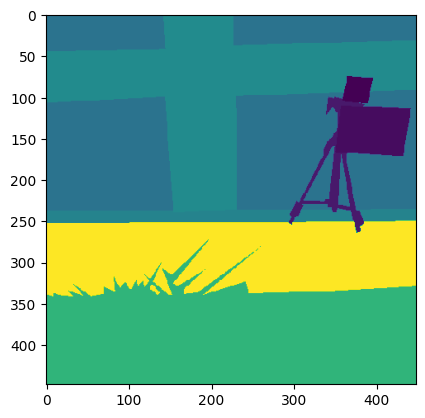

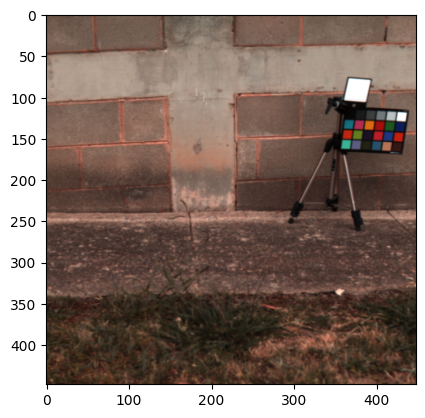

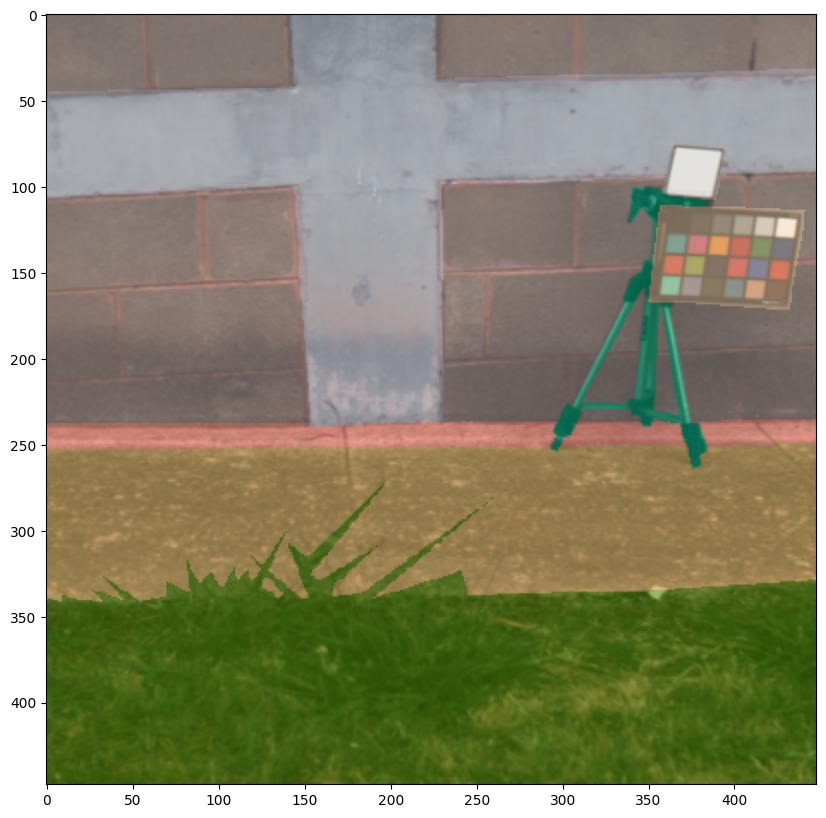

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torchvision.transforms as transforms


def visualize_map(image, segmentation_map, id2color):
    color_seg = np.zeros((segmentation_map.shape[0], segmentation_map.shape[1], 3), dtype=np.uint8) # height, width, 3
    # segmentation_map = segmentation_map.permute(1, 2, 0)*255

    # Iterate over each pixel
    for i in range(segmentation_map.shape[0]):
        for j in range(segmentation_map.shape[1]):
            # Get pixel value
            # pixel_value = segmentation_map[i, j]
            # color_seg[i,j,:] = np.array(id2color[pixel_value])
            pixel_value = int(segmentation_map[i, j].numpy())
            color_seg[i,j,:] = np.array(id2color[pixel_value])

    # Show image + mask
    img = np.array(image.permute(1, 2, 0)*255) * 0.5 + color_seg * 0.5
    # img = np.array( image.permute(1, 2, 0)*255)
    # print( color_seg)
    img = img.astype(np.uint8)
    # print( segmentation_map)
    plt.figure(figsize=(15, 10))
    plt.imshow(img)
    plt.show()
    




image, mask = train_dataset[10]
print(mask.shape, image.shape)
# print(mask)
# mask_permuted = mask.permute(1, 2, 0)
plt.imshow(mask)
plt.show()

img_permute = image.permute(1, 2, 0)
plt.imshow(img_permute)
#FIXME: running into issues here
visualize_map(image, mask, id2color)


# pixel_color = list(np.array(mask[10,10]))
# print(pixel_color)
# print(id2color.get((199, 197, 189)))
# print((id2color[0]))

# value = [80, 84, 195]
# key = get_key(id2color, pixel_color)
# print(key)


## Create PyTorch dataset

We create a regular PyTorch dataset, which prepares the examples for the model. We augment the training images by random resizing and cropping them to a fixed resolution (448x448), and normalize the color channels. This way, all our training images will have the same fixed resolution. Here we use the [Albumentations](https://albumentations.ai/) library for that purpose, but note that one can also use other libraries like Torchvision or Kornia.

 Note that the model will expect `pixel_values` of shape (batch_size, num_channels, height, width) as input. As Albumentations works on NumPy arrays (which uses a channels-last format), we make sure that the channels are first. The `labels` which the model also expects are of shape (batch_size, height, width) and indicate the ground truth label per pixel, for every example in the batch.

In [10]:

# import albumentations as A

# ADE_MEAN = np.array([123.675, 116.280, 103.530]) / 255
# ADE_STD = np.array([58.395, 57.120, 57.375]) / 255

# train_transform = A.Compose([
#     # hadded an issue with an image being too small to crop, PadIfNeeded didn't help...
#     # if anyone knows why this is happening I'm happy to read why
#     # A.PadIfNeeded(min_height=448, min_width=448),
#     # A.RandomResizedCrop(height=448, width=448),
#     A.Resize(width=448, height=448),
#     A.HorizontalFlip(p=0.5),
#     # A.Normalize(mean=ADE_MEAN, std=ADE_STD),
# ])

# val_transform = A.Compose([
#     A.Resize(width=448, height=448),
#     # A.Normalize(mean=ADE_MEAN, std=ADE_STD),

# ])


# # this is currently not working and class will need modifcation to enable this
# train_dataset = SegmentationDataset(dataset_name='freiburg', root_dir='/workspaces/HyperImages/freiburg', image_set='train', transform=train_transform)
# val_dataset = SegmentationDataset(dataset_name='freiburg', root_dir='/workspaces/HyperImages/freiburg',image_set='val', transform=val_transform)

# from torchvision.transforms import ToTensor


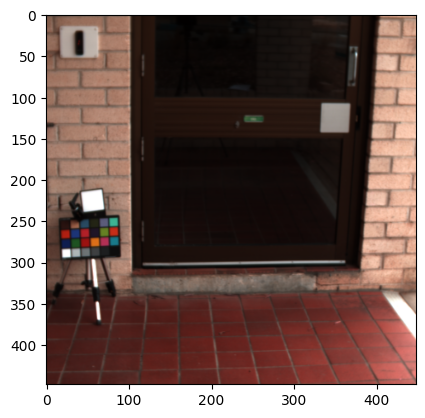

[0, 1, 2, 4, 6, 7, 8, 10, 13, 15, 16, 18, 27, 38]
['Whiteboard', 'Chessboard', 'Tripod', 'Metal-Frame', 'Brick Wall', 'Miscellaneous', 'Concrete Ground', 'Metal Door Knob/Handle', 'Concrete Footing', 'Brick Ground', 'Glass door', 'Plastic Label', 'Tiles Ground', 'Metal Smooth Door']


In [11]:
test_example, segmentation_map = train_dataset[11]
# print(segmentation_map)
img_permute = test_example.permute(1, 2, 0)
plt.imshow(img_permute)
plt.show()

# # Permute the segmentation_map
# permuted_map = segmentation_map.permute(1, 2, 0)*255
# # Convert the permuted_map to a numpy array
# permuted_map_np = permuted_map.numpy().astype(np.uint8)
# # Get a list of unique values
# unique_values = np.unique(permuted_map_np)
# print(segmentation_map)
unique_values = np.unique(segmentation_map)

# Print the list of unique values
print(unique_values.tolist())
# print([id2label[str(int(id))] for id in unique_values.tolist()] )
print([id2label[(int(id))] for id in unique_values.tolist()] )

## Create PyTorch dataloaders

Next, we create PyTorch dataloaders, which allow us to get batches of data (as neural networks are trained on batches using stochastic gradient descent or SGD). We just stack the various images and labels along a new batch dimension.

In [12]:
from torch.utils.data import DataLoader
import torch.nn.functional as F

def collate_fn(inputs):
    # batch = dict()
    # batch["pixel_values"] = torch.stack([i[0] for i in inputs], dim=0)
    # batch["labels"] = torch.stack([i[1] for i in inputs], dim=0)
    # # batch["original_images"] = [i[2] for i in inputs]
    # # batch["original_segmentation_maps"] = [i[3] for i in inputs]

    # return batch

    batch = dict()
    batch["pixel_values"] = torch.stack([i[0] for i in inputs], dim=0)
    batch["labels"] = torch.stack([i[1] for i in inputs], dim=0)
    # batch["labels"] = torch.stack([torch.from_numpy(i[1]) for i in inputs], dim=0)
    return batch

train_dataloader = DataLoader(train_dataset, batch_size=16, shuffle=True, collate_fn=collate_fn,num_workers=6)
val_dataloader = DataLoader(val_dataset, batch_size=16, shuffle=False, collate_fn=collate_fn,num_workers=6)



In [13]:
# test1 = DataLoader(val_dataset, batch_size=4, shuffle=False, collate_fn=collate_fn,num_workers=10)
batch = next(iter(train_dataloader))


for k,v in batch.items():
  if isinstance(v,torch.Tensor):
    print(k,v.shape)
    
print(batch["pixel_values"].dtype)
print(batch["labels"].dtype)


# from PIL import Image

# print(batch["pixel_values"][0].numpy().shape)
# unnormalized_image = (batch["pixel_values"][0].numpy() * np.array(ADE_STD)[:, None, None]) + np.array(ADE_MEAN)[:, None, None]
# unnormalized_image = (unnormalized_image * 255).astype(np.uint8)
# unnormalized_image = np.moveaxis(unnormalized_image, 0, -1)
# unnormalized_image = Image.fromarray(unnormalized_image)
# unnormalized_image
# print( np.unique(batch["labels"][0]).tolist())
# [id2label[str(int(id))] for id in np.unique(batch["labels"][0]).tolist()]

# visualize_map(unnormalized_image, batch["labels"][0].numpy(), id2color)

pixel_values torch.Size([16, 3, 448, 448])
labels torch.Size([16, 448, 448])
torch.float32
torch.int64


## Define model

Next, we define the model, which consists of DINOv2 as backbone + a linear classifier on top. DINOv2 is a regular vision transformer, hence it outputs "patch embeddings", meaning an embedding vector for each image patch. Since we use an image resolution of 448 pixels, and we use a DINOv2 model that has a patch resolution of 14 as seen [here](https://huggingface.co/facebook/dinov2-base/blob/main/config.json#L19), we get (448/14)**2 = 1024 patches out. So the model outputs a tensor of shape (batch_size, number of patches, hidden_size) = (batch_size, 1024, 768) for a batch of images (the model has a hidden size - also called embedding dimension - of 768 as seen [here](https://huggingface.co/facebook/dinov2-base/blob/main/config.json#L9)).

Next, we reshape this tensor to become (batch_size, 32, 32, 768), after which we apply the linear layer (below implemented as a Conv2D layer - which is equivalent to a linear transformation when you employ a kernel size of 1x1). This conv2D layer converts the patch embeddings into a logits tensor of shape (batch_size, num_labels, height, width) - which is what we need for semantic segmentation. This tensor contains scores as predicted by the model for all of the classes, for each pixel, for every example in the batch.

In [14]:


import torch
from transformers import Dinov2Model, Dinov2PreTrainedModel
from transformers.modeling_outputs import SemanticSegmenterOutput

class LinearClassifier(torch.nn.Module):
    def __init__(self, in_channels, tokenW=32, tokenH=32, num_labels=1):
        super(LinearClassifier, self).__init__()

        self.in_channels = in_channels
        self.width = tokenW
        self.height = tokenH
        self.classifier = torch.nn.Conv2d(in_channels, num_labels, (1,1))

    def forward(self, embeddings):
        embeddings = embeddings.reshape(-1, self.height, self.width, self.in_channels)
        embeddings = embeddings.permute(0,3,1,2)

        return self.classifier(embeddings)


class Dinov2ForSemanticSegmentation(Dinov2PreTrainedModel):
  def __init__(self, config):
    super().__init__(config)

    self.dinov2 = Dinov2Model(config)
    self.classifier = LinearClassifier(config.hidden_size, 32, 32, config.num_labels)

  def forward(self, pixel_values, output_hidden_states=False, output_attentions=False, labels=None):
    # use frozen features
    outputs = self.dinov2(pixel_values,
                            output_hidden_states=output_hidden_states,
                            output_attentions=output_attentions)
    # print('here',  outputs.last_hidden_state.shape)
    # get the patch embeddings - so we exclude the CLS token
    patch_embeddings = outputs.last_hidden_state[:,1:,:]

    # convert to logits and upsample to the size of the pixel values
    logits = self.classifier(patch_embeddings)
    logits = torch.nn.functional.interpolate(logits, size=pixel_values.shape[2:], mode="bilinear", align_corners=False)

    loss = None
    if labels is not None:
      # important: we're going to use 0 here as ignore index instead of the default -100
      # as we don't want the model to learn to predict background
      loss_fct = torch.nn.CrossEntropyLoss(ignore_index=0)
      loss = loss_fct(logits.squeeze(), labels.squeeze())

    return SemanticSegmenterOutput(
        loss=loss,
        logits=logits,
        hidden_states=outputs.hidden_states,
        attentions=outputs.attentions,
    )


In [15]:
# testing with model from torchhub instead of hugging face model


class LinearClassifierNew(torch.nn.Module):
    def __init__(self, in_channels, tokenW=32, tokenH=32, num_labels=1):
        super(LinearClassifierNew, self).__init__()

        self.in_channels = in_channels
        self.width = tokenW
        self.height = tokenH
        self.classifier = torch.nn.Conv2d(in_channels, num_labels, (1,1))

    def forward(self, embeddings):
        embeddings = embeddings.reshape(-1, self.height, self.width, self.in_channels)
        embeddings = embeddings.permute(0,3,1,2)

        return self.classifier(embeddings)
    
    
    
class DinoV2SemanticSegmentationRegisters(torch.nn.Module):
    def __init__(self,  repo_name="facebookresearch/dinov2", model_name="dinov2_vitb14_reg", id2label=id2label, num_labels=len(id2label),  half_precision=False, device="cuda"):
        super().__init__()
        self.repo_name = repo_name
        self.model_name = model_name
        # self.smaller_edge_size = smaller_edge_size
        self.half_precision = half_precision
        self.device = device
        if self.half_precision:
            self.dinov2 = torch.hub.load(repo_or_dir=repo_name, model=model_name).half().to(self.device)
        else:
            self.dinov2= torch.hub.load(repo_or_dir=repo_name, model=model_name).to(self.device)

         
        # Get the model's configuration
        # Get the parameters of the last layer
        # Get the parameters of the last layer
        last_layer_params = list(self.dinov2.parameters())[-1]
        # print(last_layer_params.shape)
        patch_descriptor_size = last_layer_params.shape[0]
        # print(patch_descriptor_size)
        # # Get the patch descriptor size
        # patch_descriptor_size = last_layer_params.shape[1]
        # print(patch_descriptor_size)
        self.classifier = LinearClassifierNew(patch_descriptor_size, 32, 32, num_labels)
        self.classifier = self.classifier.to(self.device)
        # # self.model.eval()
        # for param in self.model.parameters():
        #     param.requires_grad = False
            
        # # Unfreeze the parameters in the linear layers
        # # for param in self.model.parameters():
        # #     print(param)
        # for name, module in self.model.named_children():
        #     # print(f"{name}: {module}")
        #     # print(name)
        #     if name =='linear_head':
        #         #print named children
        #         # print(module)
        #         for param in module.parameters():
        #             param.requires_grad = True
                
        
        # self.transform = transforms.Compose([
        #     transforms.Resize(size=smaller_edge_size, interpolation=transforms.InterpolationMode.BICUBIC, antialias=True),
        #     transforms.ToTensor(),
        #     transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)), # imagenet defaults
        # ])
        # print(self.model)
        
        for name, param in self.dinov2.named_parameters():
            # print(name)
            #   if name.startswith("dinov2"):
            param.requires_grad = False

    def __call__(self, pixel_values, labels=None):
        pixel_values = pixel_values.to(self.device)
        if labels is not None:
            labels = labels.to(self.device)
        return self.forward(pixel_values=pixel_values, labels=labels)
    
    def forward(self, pixel_values, output_hidden_states=False, output_attentions=False, labels=None):
       
        
        
        # use frozen features
        # outputs = self.dinov2(pixel_values,
        #                         output_hidden_states=output_hidden_states,
        #                         output_attentions=output_attentions)
        # outputs = self.dinov2(pixel_values)
        patch_embeddings = self.dinov2.get_intermediate_layers(pixel_values)[0].squeeze()
        
        # print('here',patch_embeddings.shape)
        
        # get the patch embeddings - so we exclude the CLS token
        # patch_embeddings = outputs.last_hidden_state[:,1:,:]

        # convert to logits and upsample to the size of the pixel values
        logits = self.classifier(patch_embeddings)
        logits = torch.nn.functional.interpolate(logits, size=pixel_values.shape[2:], mode="bilinear", align_corners=False)

        loss = None
        if labels is not None:
            # important: we're going to use 0 here as ignore index instead of the default -100
            # as we don't want the model to learn to predict background
            loss_fct = torch.nn.CrossEntropyLoss(ignore_index=0)
            loss = loss_fct(logits.squeeze(), labels.squeeze())
        
        return  SemanticSegmenterOutput(
            loss=loss,
            logits=logits,
            # hidden_states=outputs.hidden_states,
            # attentions=outputs.attentions,
        )
        
    
# model = DinoV2SemanticSegmentationRegisters()    #torch.hub.load('facebookresearch/dinov2', 'dinov2_vitb14_reg_lc').eval().to(device)

In [16]:

# #select model to use 
# model = Dinov2ForSemanticSegmentation.from_pretrained("facebook/dinov2-base", id2label=id2label, num_labels=len(id2label))
# for name, param in model.named_parameters():
#   if name.startswith("dinov2"):
#     param.requires_grad = False


model = DinoV2SemanticSegmentationRegisters()  
    

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitb14/dinov2_vitb14_reg4_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitb14_reg4_pretrain.pth
100%|██████████| 330M/330M [00:09<00:00, 38.0MB/s] 


Important: we don't want to train the DINOv2 backbone, only the linear classification head. Hence we don't want to track any gradients for the backbone parameters. This will greatly save us in terms of memory used:

In [17]:
print(batch["labels"].min(), batch["labels"].max())
print(batch["pixel_values"].shape, batch["labels"].shape)
print(len(id2label))


outputs = model(pixel_values=batch["pixel_values"], labels=batch["labels"])
# pixel_values = batch["pixel_values"].to("cuda")
# labels = batch["labels"].to("cuda")
# # outputs = model.forward(pixel_values)
# outputs = model.forward(pixel_values=pixel_values, labels=labels)

print(outputs.logits.shape)
print(outputs.loss)

tensor(0) tensor(43)
torch.Size([16, 3, 448, 448]) torch.Size([16, 448, 448])
45
torch.Size([16, 45, 448, 448])
tensor(3.8333, device='cuda:0', grad_fn=<NllLoss2DBackward0>)


In [18]:
import evaluate

metric = evaluate.load("mean_iou")
metric_val = evaluate.load("mean_iou")

from torch.optim import AdamW
from tqdm.auto import tqdm

# training hyperparameters
# NOTE: I've just put some random ones here, not optimized at all
# feel free to experiment, see also DINOv2 paper
learning_rate = 5e-5
epochs = 50

optimizer = AdamW(model.parameters(), lr=learning_rate)

# put model on GPU (set runtime to GPU in Google Colab)
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

# put model in training mode
# model.train()

history_loss_train = []
history_loss_val = []

history_mean_iou_train = []
history_mean_iou_val = []

history_mean_accuracy_train = []
history_mean_accuracy_val = []

for epoch in range(epochs):
  print("Epoch:", epoch)
  model.train()
  for idx, batch in enumerate(tqdm(train_dataloader)):
      torch.cuda.synchronize()
      pixel_values = batch["pixel_values"].to(device)
      labels = batch["labels"].to(device)

      # forward pass
      outputs = model(pixel_values, labels=labels)
      loss = outputs.loss

      # zero the parameter gradients
      optimizer.zero_grad()
      
      loss.backward()
      optimizer.step()

      

      # evaluate
      
      with torch.no_grad():
        predicted = outputs.logits.argmax(dim=1)

        # note that the metric expects predictions + labels as numpy arrays
        
        metric.add_batch(predictions=predicted.detach().cpu().numpy(), references=labels.detach().cpu().numpy())

  
  metrics = metric.compute(num_labels=len(id2label),
                            ignore_index=0,
                            reduce_labels=False,
  )

  # print("Loss:", loss.item())
  # print("Mean_iou:", metrics["mean_iou"])
  # print("Mean accuracy:", metrics["mean_accuracy"])
  history_loss_train.append(loss.item())
  history_mean_iou_train.append(metrics["mean_iou"])
  history_mean_accuracy_train.append(metrics["mean_accuracy"])
  
  
  
  model.eval()
  # # # validation
  for idx, batch in enumerate(tqdm(val_dataloader)):
    pixel_values = batch["pixel_values"].to(device)
    labels = batch["labels"].to(device)


    # forward pass
    outputs = model(pixel_values, labels=labels)
    val_loss = outputs.loss

    with torch.no_grad():
        predicted = outputs.logits.argmax(dim=1)

        # note that the metric expects predictions + labels as numpy arrays
        
        metric_val.add_batch(predictions=predicted.detach().cpu().numpy(), references=labels.detach().cpu().numpy())

  metrics_val = metric_val.compute(num_labels=len(id2label),
                          ignore_index=-1,
                          reduce_labels=False,
  )
  history_loss_val.append(val_loss.item())
  history_mean_iou_val.append(metrics_val["mean_iou"])
  history_mean_accuracy_val.append(metrics_val["mean_accuracy"])
  
  # print("Train Loss: ", loss.item())
  # print("Train Mean_iou: ", metrics["mean_iou"])
  # print("Train Mean_accuracy: ", metrics["mean_accuracy"])
  
  
  print("Train Loss: ", loss.item(), " Test Loss: ", val_loss.item())
  print("Train Mean_iou: ", metrics["mean_iou"], " Test Mean_iou: ", metrics_val["mean_iou"])
  print("Train Mean_accuracy: ", metrics["mean_accuracy"], " Test Mean_accuracy: ", metrics_val["mean_accuracy"])
  
  

Epoch: 0


  0%|          | 0/25 [00:00<?, ?it/s]/usr/local/lib/python3.8/dist-packages/datasets/features/image.py:348: UserWarning: Downcasting array dtype int64 to int32 to be compatible with 'Pillow'
  warnings.warn(f"Downcasting array dtype {dtype} to {dest_dtype} to be compatible with 'Pillow'")
100%|██████████| 25/25 [02:38<00:00,  6.35s/it]
/root/.cache/huggingface/modules/evaluate_modules/metrics/evaluate-metric--mean_iou/9e450724f21f05592bfb0255fe2fa576df8171fa060d11121d8aecfff0db80d0/mean_iou.py:260: RuntimeWarning: invalid value encountered in divide
  acc = total_area_intersect / total_area_label
100%|██████████| 3/3 [00:25<00:00,  8.60s/it]


Train Loss:  3.455080032348633  Test Loss:  3.4298126697540283
Train Mean_iou:  0.014477684063019823  Test Mean_iou:  0.026071539014667123
Train Mean_accuracy:  0.0481373882085715  Test Mean_accuracy:  0.07241327149042036
Epoch: 1


100%|██████████| 3/3 [00:39<00:00, 13.09s/it]


Train Loss:  3.2448954582214355  Test Loss:  3.1509697437286377
Train Mean_iou:  0.030643006495168545  Test Mean_iou:  0.04627241417841642
Train Mean_accuracy:  0.07839440258360704  Test Mean_accuracy:  0.11810374109619863
Epoch: 2


...

Train Loss:  0.8761659860610962  Test Loss:  0.8446449637413025
Train Mean_iou:  0.37670256685568354  Test Mean_iou:  0.3437944513901386
Train Mean_accuracy:  0.4571855855394034  Test Mean_accuracy:  0.46701235127770374
Epoch: 48


100%|██████████| 3/3 [00:24<00:00,  8.25s/it]


Train Loss:  0.6211701035499573  Test Loss:  0.8359180688858032
Train Mean_iou:  0.3811951714744665  Test Mean_iou:  0.34536554866723207
Train Mean_accuracy:  0.46200745656476067  Test Mean_accuracy:  0.46921191469394924
Epoch: 49


100%|██████████| 3/3 [00:25<00:00,  8.47s/it]


Train Loss:  1.1360431909561157  Test Loss:  0.8288133144378662
Train Mean_iou:  0.38536671439564074  Test Mean_iou:  0.3478863755499206
Train Mean_accuracy:  0.466377788715935  Test Mean_accuracy:  0.471862324290228


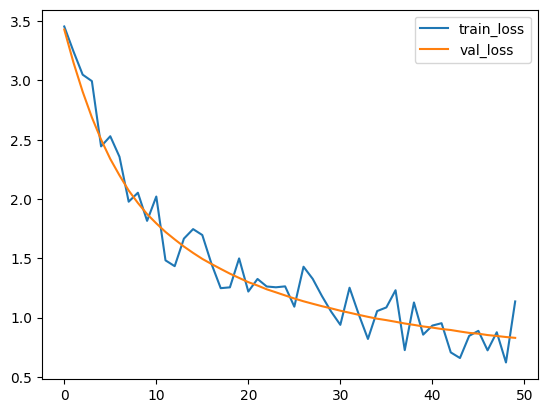

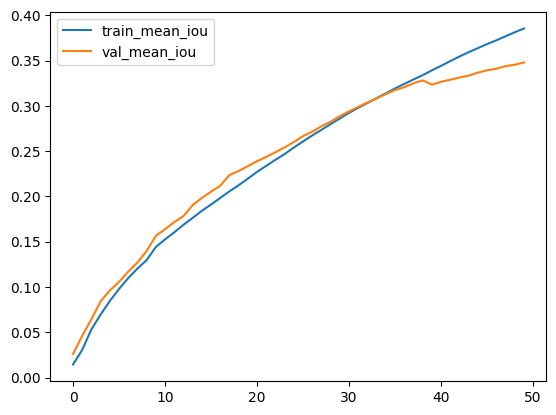

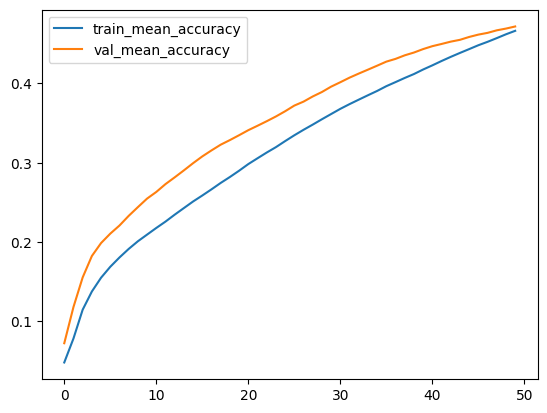

In [19]:
# plot the training and validation loss
plt.plot(history_loss_train, label="train_loss")
plt.plot(history_loss_val, label="val_loss")
plt.legend()
plt.show()

# # plot the training and validation mean iou
plt.plot(history_mean_iou_train, label="train_mean_iou")
plt.plot(history_mean_iou_val, label="val_mean_iou")
plt.legend()
plt.show()

# plot the training and validation mean accuracy
plt.plot(history_mean_accuracy_train, label="train_mean_accuracy")
plt.plot(history_mean_accuracy_val, label="val_mean_accuracy")
plt.legend()
plt.show()

In [20]:
#Save model
# torch.save(model.state_dict(), "/workspaces/HyperTools/examples/segmentation_model.pt")

Now test.

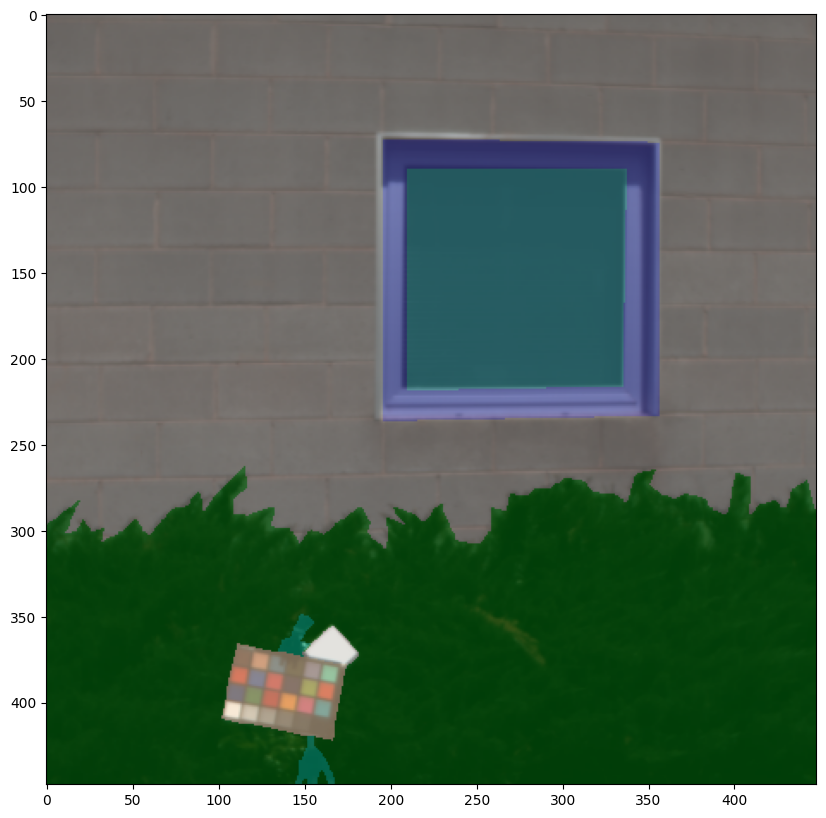

/tmp/ipykernel_15772/565960373.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  pixel_values = torch.tensor(test_image)


torch.Size([1, 3, 448, 448])


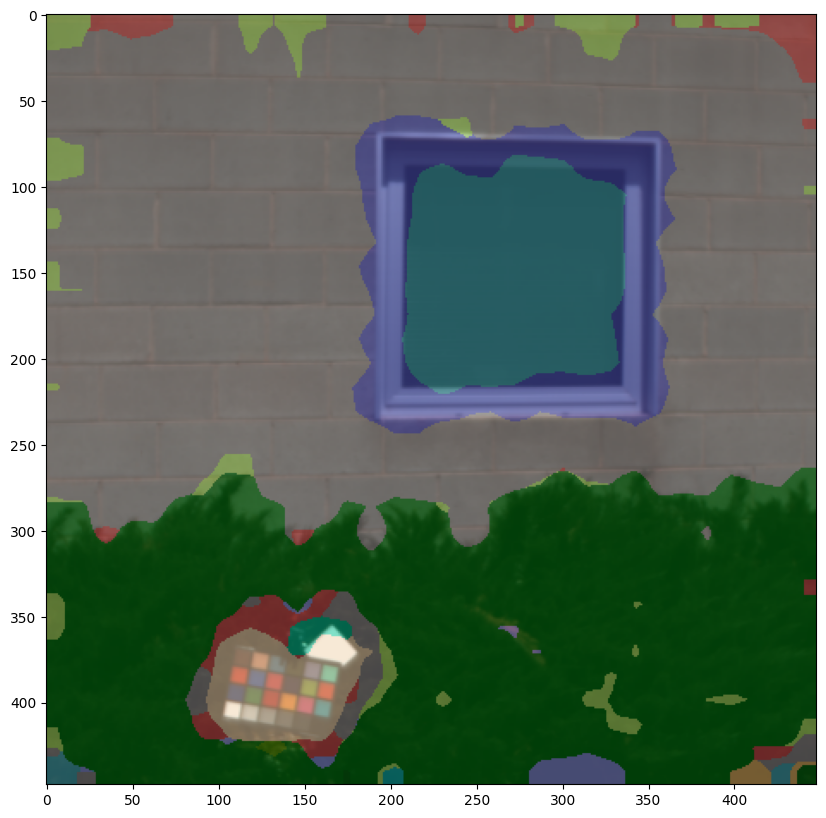

In [21]:
from PIL import Image

test_image, test_mask = val_dataset[7]
img_permute = test_image.permute(1, 2, 0)
# plt.imshow(test_mask)
# plt.show()
visualize_map(test_image, test_mask, id2color)

# pixel_values = val_transform(image=np.array(test_image))["image"]
pixel_values = torch.tensor(test_image)
pixel_values = pixel_values.unsqueeze(0) # convert to (batch_size, num_channels, height, width)
print(pixel_values.shape)

with torch.no_grad():
  outputs = model(pixel_values.to(device))

# upsampled_logits = torch.nn.functional.interpolate(outputs.logits,
#                                                    size=test_image.size[::-1],
#                                                    mode="bilinear", align_corners=False)
upsampled_logits = torch.nn.functional.interpolate(outputs.logits,
                                                   size=(test_image.shape[-2], test_image.shape[-1]),
                                                   mode="bilinear", align_corners=False)

predicted_map = upsampled_logits.argmax(dim=1)

visualize_map(test_image, predicted_map.squeeze().cpu(), id2color)



In [22]:
#Function takes in predicted map and saves the image

def save_model_result(test_image, predicted_map,  id2color, imageNumber):
    
    # print(predicted_map.shape, test_image.shape)
    # color_seg = np.zeros((predicted_map.shape[1], predicted_map.shape[2], 3), dtype=np.uint8) # height, width, 3

    # # Iterate over each pixel
    # for i in range(predicted_map.shape[1]):
    #     for j in range(predicted_map.shape[2]):
    #         # Get pixel value
    #         pixel_value = int(predicted_map[0, i, j].item())
    #         color_seg[i,j,:] = np.array(id2color[str(pixel_value)]) 
            
    # # Create overlaid image
    # img = np.array(test_image.permute(1, 2, 0)*255) * 0.5 + color_seg * 0.5
    # img = img.astype(np.uint8)
    
    # pixel_values = torch.tensor(test_image)
    pixel_values = test_image.clone().detach()
    pixel_values = pixel_values.unsqueeze(0) # convert to (batch_size, num_channels, height, width)
    # print(pixel_values.shape)

    with torch.no_grad():
        outputs = model(pixel_values.to(device))
    upsampled_logits = torch.nn.functional.interpolate(outputs.logits,
                                                   size=(test_image.shape[-2], test_image.shape[-1]),
                                                   mode="bilinear", align_corners=False)

    predicted_map = upsampled_logits.argmax(dim=1).squeeze().cpu()

    color_seg = np.zeros((predicted_map.shape[0], predicted_map.shape[1], 3), dtype=np.uint8)

    # Iterate over each pixel
    for i in range(predicted_map.shape[0]):
        for j in range(predicted_map.shape[1]):
            # Get pixel value
            # pixel_value = segmentation_map[i, j]
            # color_seg[i,j,:] = np.array(id2color[pixel_value])
            pixel_value = int(predicted_map[i, j].numpy())            
            color_seg[i,j,:] = np.array(id2color[pixel_value])

    # Show image + mask
    img = np.array(test_image.permute(1, 2, 0)*255) * 0.5 + color_seg * 0.5
    # img = np.array( image.permute(1, 2, 0)*255)
    # print( color_seg)
    img = img.astype(np.uint8)
    
    
    Image.fromarray(img).save(f"/workspaces/HyperImages/export/segmentation_predicted_maps/image{imageNumber}.png")
    
def save_GT(image, segmentation_map, id2color, imageNumber):
    
    
    color_seg = np.zeros((segmentation_map.shape[0], segmentation_map.shape[1], 3), dtype=np.uint8) # height, width, 3
    # segmentation_map = segmentation_map.permute(1, 2, 0)*255

    # Iterate over each pixel
    for i in range(segmentation_map.shape[0]):
        for j in range(segmentation_map.shape[1]):
            # Get pixel value
            # pixel_value = segmentation_map[i, j]
            # color_seg[i,j,:] = np.array(id2color[pixel_value])
            pixel_value = int(segmentation_map[i, j].numpy())
            color_seg[i,j,:] = np.array(id2color[pixel_value])

    # Show image + mask
    img = np.array(image.permute(1, 2, 0)*255) * 0.5 + color_seg * 0.5
    # img = np.array( image.permute(1, 2, 0)*255)
    # print( color_seg)
    img = img.astype(np.uint8)
    
    
    
    # print(predicted_map.shape)
    # color_seg = np.zeros((predicted_map.shape[1], predicted_map.shape[2], 3), dtype=np.uint8) # height, width, 3

    # # Iterate over each pixel
    # for i in range(predicted_map.shape[1]):
    #     for j in range(predicted_map.shape[2]):
    #         # Get pixel value
    #         pixel_value = int(predicted_map[0, i, j].item())
    #         color_seg[i,j,:] = np.array(id2color[str(pixel_value)]) 
            
    # # Show image + mask
    # img = np.array(image.permute(1, 2, 0)*255) * 0.5 + color_seg * 0.5
    # img = img.astype(np.uint8)
    # Save image
    Image.fromarray(img).save(f"/workspaces/HyperImages/export/segmentation_gt_maps/image{imageNumber}.png")

#Save files
#only save first few right now during development
for index in range(0, len(val_dataset)):
# for index in range(0, 3):
    test_image, test_mask = val_dataset[index]
    
    save_GT(test_image, test_mask, id2color, index)
    save_model_result(test_image, test_mask, id2color, index)
    
    # img_permute = test_image.permute(1, 2, 0)
    
    
    # # pixel_values = val_transform(image=np.array(test_image))["image"]
    # pixel_values = torch.tensor(test_image)
    # pixel_values = pixel_values.unsqueeze(0) # convert to (batch_size, num_channels, height, width)
    # print(pixel_values.shape)

    # with torch.no_grad():
    #     outputs = model(pixel_values.to(device))

    # # upsampled_logits = torch.nn.functional.interpolate(outputs.logits,
    # #                                                    size=test_image.size[::-1],
    # #                                                    mode="bilinear", align_corners=False)
    # upsampled_logits = torch.nn.functional.interpolate(outputs.logits,
    #                                                 size=(test_image.shape[-2], test_image.shape[-1]),
    #                                                 mode="bilinear", align_corners=False)

    # predicted_map = upsampled_logits.argmax(dim=1)
    
    # save_overlaid(test_image, predicted_map, index)


FileNotFoundError: [Errno 2] No such file or directory: '/workspaces/HyperImages/export/segmentation_gt_maps/image0.png'